# What is the soil at the Moon's south pole made of?

**Reading Chandrayaan-3's rover chemistry from the public archive.**

The Pragyan rover carried two instruments that read the elements in the soil:

- **APXS** (Alpha Particle X-ray Spectrometer, PRL Ahmedabad) bombards the ground with alpha particles and X-rays from curium-244 sources, then counts the X-rays each element gives back.
- **LIBS** (Laser Induced Breakdown Spectroscope, LEOS Bengaluru) fires a laser that turns a speck of soil into plasma, then records the light that plasma emits.

Published results to compare against:

- Vadawale et al. 2024, *Nature* 633, 327: **23 APXS measurements** within 50 m of the landing site show a **uniform** soil of ferroan anorthosite, with more magnesium than expected.
- Sinha et al. 2025, *Communications Earth & Environment*: **sulphur at 900–1,400 ppm**.
- ISRO, 29 Aug 2023: LIBS "unambiguously confirms" **sulphur**, along with Al, Ca, Fe, Cr, Ti, Mn, Si and O.


In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*(plain CSV|label names missing).*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from isda import ch3

RAW = Path("../data/raw/ch3")  # unzipped PRADAN downloads; see the README
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

def days(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

def credit(fig, payload):
    fig.text(0.99, 0.005, f"Data: Chandrayaan-3 {payload}, ISRO / ISSDC PRADAN · © reserved ISRO",
             ha="right", va="bottom", fontsize=7, color="0.45")

# X-ray line energies (keV) and optical emission lines (nm) used to label peaks.
XRAY = {"Na": 1.04, "Mg": 1.25, "Al": 1.49, "Si": 1.74, "S": 2.31, "K": 3.31,
        "Ca": 3.69, "Ca Kβ": 4.01, "Ti": 4.51, "Cr": 5.41, "Mn": 5.90, "Fe": 6.40, "Fe Kβ": 7.06}

## 1. APXS: one spectrum per rover stop

`ch3.apxs()` returns the calibrated spectrum of one stop, counts against energy. Some stops only hold spectra of the on-board calibration target, so they're skipped.

23 of 28 stops have a lunar-soil spectrum (the paper used 23)


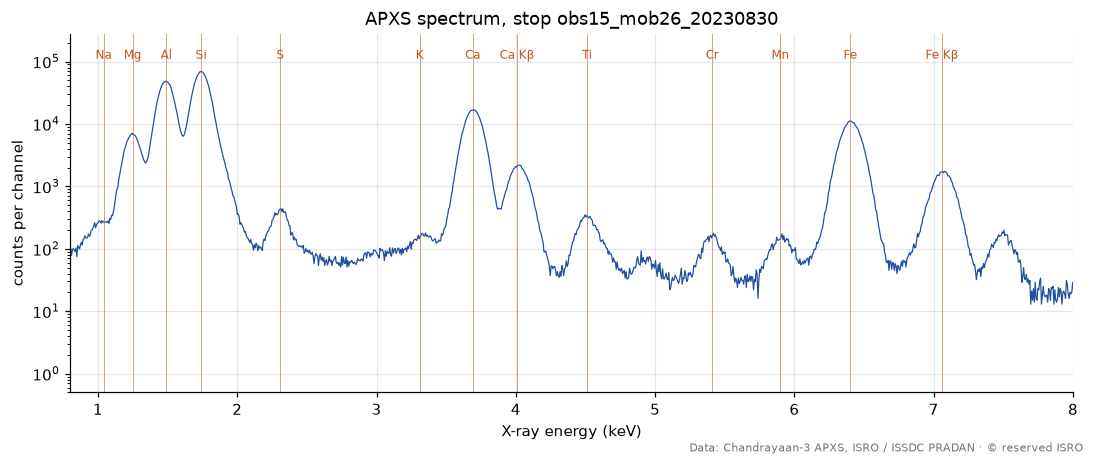

In [2]:
stops = sorted((RAW / "apxs/apx/data").glob("obs*"))
spectra = {}
for stop in stops:
    try:
        spectra[stop.name] = ch3.apxs(stop).COUNTS
    except FileNotFoundError:
        pass
print(f"{len(spectra)} of {len(stops)} stops have a lunar-soil spectrum (the paper used 23)")

best = max(spectra, key=lambda k: spectra[k].sum())
s = spectra[best]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.semilogy(s.index, s.clip(lower=0.5), lw=0.8, color="#1f4e9c")
for el, e in XRAY.items():
    ax.axvline(e, color="#c0561a", lw=0.6, alpha=0.6)
    ax.text(e, s.max() * 1.6, el, ha="center", fontsize=8, color="#c0561a")
ax.set_xlim(0.8, 8)
ax.set_ylim(0.5, s.max() * 4)
ax.set_xlabel("X-ray energy (keV)")
ax.set_ylabel("counts per channel")
ax.set_title(f"APXS spectrum, stop {best}")
credit(fig, "APXS")
fig.tight_layout()

## 2. Is the soil the same everywhere?

The paper's headline is that the 23 spots look alike. A quick test: net counts in each element's line (minus the continuum on either side), relative to silicon, stop by stop. These are **count ratios, not abundances**: turning them into weight percent needs a fit with the instrument response, which is the next step. But if the soil changed from stop to stop, these ratios would scatter.

Odd one out: obs26_mob42_20230901, Mg ratio 0.0035 against a median of 0.029


,median ratio to Si,typical stop-to-stop scatter (%)
Mg,0.029,13.603
Al,0.668,0.651
Ca,0.241,0.833
Fe,0.116,2.972
S,0.005,5.576


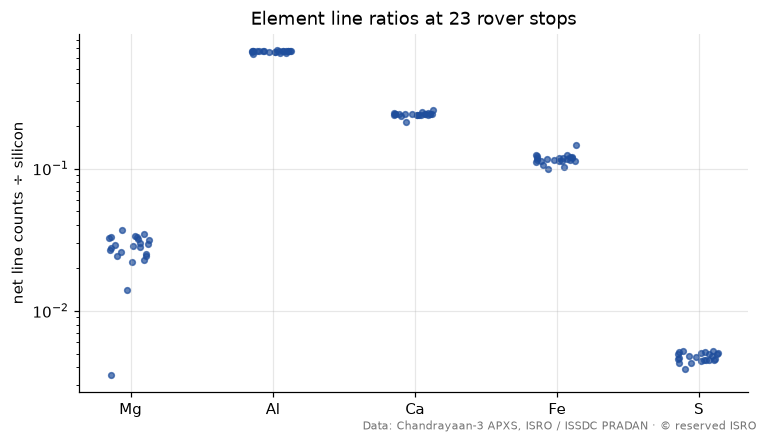

In [3]:
def net_counts(spec, e, w=0.06):
    peak = spec.loc[e - w:e + w]
    side = (spec.loc[e - 3 * w:e - w].mean() + spec.loc[e + w:e + 3 * w].mean()) / 2
    return peak.sum() - side * len(peak)

lines = pd.DataFrame({k: {el: net_counts(v, e) for el, e in XRAY.items()} for k, v in spectra.items()}).T
ratios = lines[["Mg", "Al", "Ca", "Fe", "S"]].div(lines.Si, axis=0)

fig, ax = plt.subplots(figsize=(7, 4))
for i, el in enumerate(ratios.columns):
    ax.scatter(np.full(len(ratios), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(ratios)),
               ratios[el], s=14, color="#1f4e9c", alpha=0.7)
ax.set_xticks(range(len(ratios.columns)), ratios.columns)
ax.set_yscale("log")
ax.set_ylabel("net line counts ÷ silicon")
ax.set_title(f"Element line ratios at {len(ratios)} rover stops")
credit(fig, "APXS")
fig.tight_layout()

# Median absolute deviation, so one odd stop doesn't dominate; that stop is named below.
summary = pd.DataFrame({"median ratio to Si": ratios.median(),
                        "typical stop-to-stop scatter (%)": (ratios - ratios.median()).abs().median() / ratios.median() * 100})
odd = ratios.Mg.idxmin()
print(f"Odd one out: {odd}, Mg ratio {ratios.Mg[odd]:.4f} against a median of {ratios.Mg.median():.3f}")
summary.round(3)

## 3. Sulphur in APXS

Sulphur's K-alpha line sits at 2.31 keV, between silicon and potassium. Here it is at every stop:

Sulphur net counts per stop: median 1,017, smallest 189


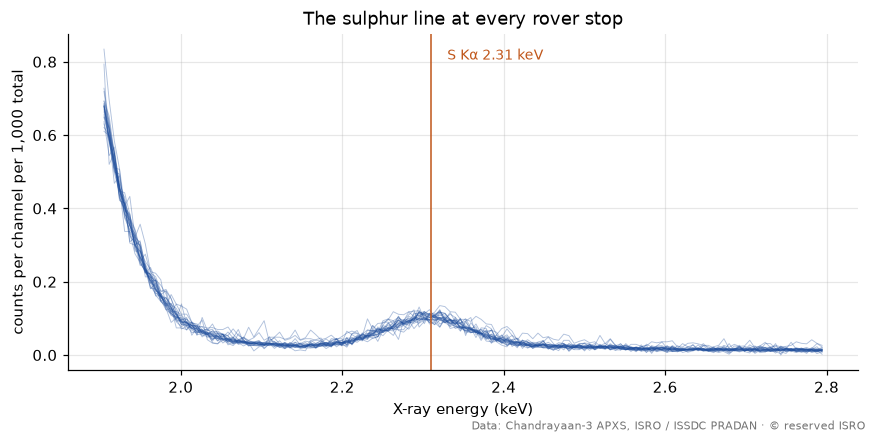

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for k, v in spectra.items():
    z = v.loc[1.9:2.8]
    ax.plot(z.index, z / v.sum() * 1e3, lw=0.6, color="#1f4e9c", alpha=0.35)
ax.axvline(XRAY["S"], color="#c0561a", lw=1)
ax.text(XRAY["S"] + 0.02, ax.get_ylim()[1] * 0.92, "S Kα 2.31 keV", color="#c0561a", fontsize=9)
ax.set_xlabel("X-ray energy (keV)")
ax.set_ylabel("counts per channel per 1,000 total")
ax.set_title("The sulphur line at every rover stop")
credit(fig, "APXS")
fig.tight_layout()
print(f"Sulphur net counts per stop: median {lines.S.median():,.0f}, smallest {lines.S.min():,.0f}")

## 4. LIBS: plasma light

`ch3.libs()` returns every laser shot of one product as a spectrum (counts against wavelength) plus per-shot settings. Each product includes laser-off shots, which record the detector's background. Subtracting them from the laser-on shots leaves the plasma light. Stacking all products (median) brings out lines common to the whole traverse.

234 of 301 products have both laser-on and laser-off shots


,measured (nm),shift (nm),peak ÷ noise
Mg⁺ 280.3,281.93,1.66,26.26
O 777.2,777.97,0.78,8.90
Al 309.3,310.46,1.19,7.85
Si 251.6,253.20,1.59,7.21
Ca⁺/Al 393–396,395.50,0.60,4.44
Ti 334.9,336.58,1.64,2.99
Si 288.2,289.73,1.57,2.62
Ca 422.7,422.80,0.13,2.24
S 182.0,183.02,0.99,2.15
K 766.5,767.12,0.63,2.04


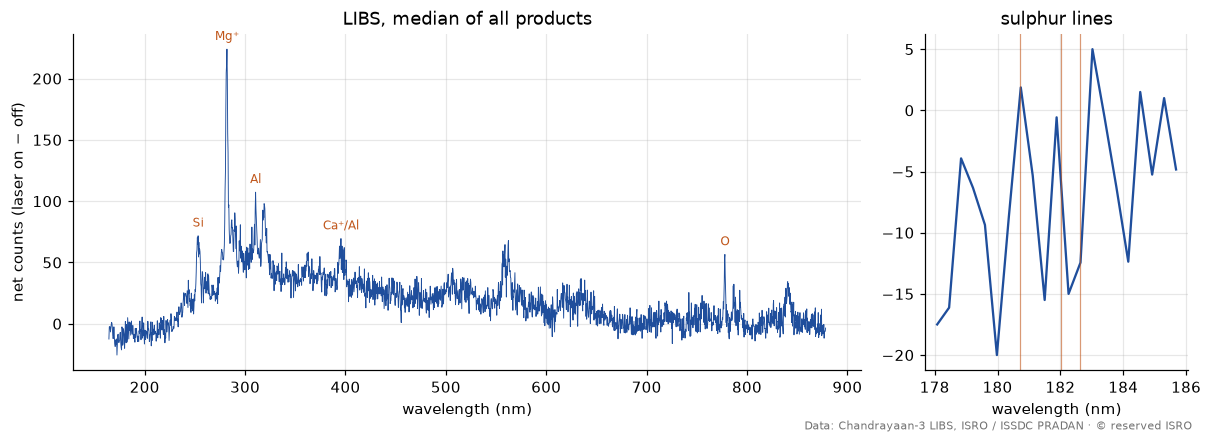

In [5]:
products = sorted((RAW / "libs/lib-v2/data/calibrated").glob("*/*/*_l1.xml"))
net = []
for p in products:
    spec, shots = ch3.libs(p)
    fired = shots["Laser Fire Status"].astype(int).eq(1).to_numpy()
    if fired.any() and (~fired).any():
        net.append(spec[fired].mean() - spec[~fired].mean())
stack = pd.concat(net, axis=1).median(axis=1)
noise = stack.diff().abs().median()
print(f"{len(net)} of {len(products)} products have both laser-on and laser-off shots")

# Reference wavelengths (NIST). Ca⁺ 393.4/396.8 and Al 396.2 blend at this resolution, so they're one entry.
OPTICAL = {"Si 251.6": 251.61, "Mg⁺ 280.3": 280.27, "Si 288.2": 288.16, "Al 309.3": 309.27, "Ca⁺/Al 393–396": 394.9,
           "Ca 422.7": 422.67, "Na 589.0": 588.99, "H 656.3": 656.28, "K 766.5": 766.49, "O 777.2": 777.19,
           "S 180.7": 180.73, "S 182.0": 182.03, "Ti 334.9": 334.94, "Cr 425.4": 425.43, "Mn 403.1": 403.08}
# The archived wavelength axis is off by up to ~2 nm before the manual's temperature correction,
# so each line's peak is searched for within ±2 nm.
def measure(nm):
    z = stack.loc[nm - 2:nm + 2]
    return {"measured (nm)": z.idxmax(), "shift (nm)": z.idxmax() - nm,
            "peak ÷ noise": (z.max() - stack.loc[nm - 8:nm + 8].median()) / noise}
lines_libs = pd.DataFrame({k: measure(v) for k, v in OPTICAL.items()}).T.sort_values("peak ÷ noise", ascending=False)

fig, (ax, az) = plt.subplots(1, 2, figsize=(11, 4), width_ratios=[3, 1])
ax.plot(stack.index, stack, lw=0.6, color="#1f4e9c")
for k, nm in OPTICAL.items():
    if lines_libs.loc[k, "peak ÷ noise"] >= 3:
        at = lines_libs.loc[k, "measured (nm)"]
        ax.annotate(k.split()[0], (at, stack[at]), textcoords="offset points",
                    xytext=(0, 6), ha="center", fontsize=8, color="#c0561a")
ax.set_xlabel("wavelength (nm)")
ax.set_ylabel("net counts (laser on − off)")
ax.set_title("LIBS, median of all products")
z = stack.loc[178:186]
az.plot(z.index, z, color="#1f4e9c")
for nm in (180.73, 182.03, 182.62):
    az.axvline(nm, color="#c0561a", lw=0.8, alpha=0.6)
az.set_title("sulphur lines")
az.set_xlabel("wavelength (nm)")
credit(fig, "LIBS")
fig.tight_layout()
lines_libs.astype(float).round(2)

## What this reproduces, and what it doesn't

- **Reproduced:** APXS has exactly the paper's **23 soil measurements**, and the element ratios barely change between stops, consistent with a **uniform** soil around Shiv Shakti point.
- **Reproduced:** **sulphur** shows clearly in APXS at every stop.
- **Worth a closer look:** one stop (named above) has a tenth of the usual magnesium line. It could be real or an artefact of this simple line-sum next to the strong aluminium peak; the full fit will tell.
- **Partly reproduced:** a simple LIBS stack shows **magnesium, oxygen, aluminium and silicon**, plus the calcium/aluminium blend near 395 nm. Magnesium's 280 nm line is the strongest in the whole stack, which fits the APXS finding of a Mg-rich soil. **Titanium is borderline** (about 3× the noise, at the same shift as the other ultraviolet lines). **Sulphur, chromium and manganese don't stand out** this way.
- **Found along the way:** the archived LIBS wavelengths run long by about 1.6 nm in the ultraviolet (Si, Mg) and 0.8 nm at 777 nm (O). The LIBS user manual describes a correction for detector temperature that isn't applied to the calibrated product. The peak near 562 nm sits close to twice the Mg line's wavelength, possibly the grating's second order. ISRO's LIBS results used the full pipeline in the LIBS user manual (denoising, baseline removal, and wavelength corrections for detector temperature and working distance), at single spots rather than a traverse-wide median.

**Next steps**
1. Fit the APXS spectra with the instrument response (`*_rsp`) to get weight-percent oxides and compare with the paper's values.
2. Implement the LIBS manual's processing steps, then look for sulphur spot by spot.

---
**Acknowledgements.**
APXS: We acknowledge the use of data from the APXS instrument on the rover of the Chandrayaan-3 mission of the Indian Space Research Organisation (ISRO), archived at the Indian Space Science Data Centre (ISSDC). APXS experiment is designed and developed by the Physical Research Laboratory (PRL), Ahmedabad with support from Space Applications Center (SAC), Ahmedabad and U.R Rao Satellite Center (URSC), Bangalore.
LIBS: We acknowledge the use of the data recorded by the LIBS instrument aboard the ISRO Pragyan rover, Chandrayaan-3 mission, archived at the Indian Space Science Data Centre (ISSDC). The LIBS instrument is developed at the Laboratory for Electro-Optics Systems (LEOS), Bengaluru with support from U.R.Rao Satellite Centre (URSC), Bengaluru.
Figures carry "© reserved ISRO" as the data terms require.
